# Email campaign A/B/n test: did it work, for whom, and who should get it next time?

A narrated walkthrough of the analysis in this repo. Data: Kevin Hillstrom's MineThatData E-Mail Analytics
Challenge (2008): 64,000 recent customers were randomly split into three equal groups. One group got an email
featuring men's merchandise, one an email featuring women's merchandise, one no email. Visits, purchases and
spend were tracked for the two weeks after the send.

How to read it: `src/run_all.py` rebuilds every table in `results/` and every chart in `images/` from the raw
CSV. This notebook re-derives the key tests by hand, then reads those files. The markdown cells contain no
result numbers; every number is printed by a code cell.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
from IPython.display import Image, display
from scipy import stats

import config as cfg
import prepare
import stats_utils as su

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
R = cfg.RESULTS


def show(path):
    display(Image(filename=str(ROOT / "images" / path), width=900))


df = prepare.load_clean()
print(f"{len(df):,} customers x {df.shape[1]} columns")
df.head()

64,000 customers x 19 columns


,row_id,arm,segment,recency,recency_bucket,history,history_segment,history_bucket,mens,womens,purchase_history,newbie,customer_type,zip_code,channel,visit,conversion,spend,log_history
0,1,Womens,Womens E-Mail,10,10-12,142.4400,2) $100 - $200,$100-$199,1,0,Mens only,0,Existing customer,Suburban,Phone,0,0,0.0000,4.9589
1,2,Control,No E-Mail,6,4-6,329.0800,3) $200 - $350,$200-$349,1,1,Both,1,New customer,Rural,Web,0,0,0.0000,5.7963
2,3,Womens,Womens E-Mail,7,7-9,180.6500,2) $100 - $200,$100-$199,0,1,Womens only,1,New customer,Suburban,Web,0,0,0.0000,5.1966
3,4,Mens,Mens E-Mail,9,7-9,675.8300,5) $500 - $750,$350+,1,0,Mens only,1,New customer,Rural,Web,0,0,0.0000,6.5159
4,5,Womens,Womens E-Mail,2,1-3,45.3400,1) $0 - $100,Under $100,1,0,Mens only,0,Existing customer,Urban,Web,0,0,0.0000,3.8142


## 0. The data and its quirks

No missing values, but a few things to know before analysing: a typo in the ZIP-code labels, many exact
duplicate rows (there is no customer ID), and a spend variable that is zero for almost everyone and appears to
be capped at the top. The checks below run in SQL (DuckDB, `sql/01_data_quality.sql`).

In [2]:
dq = pd.read_csv(R / "data_quality.csv", keep_default_na=False)
dq

,check_name,value,note
0,rows,"64,000.0000",one row per customer; the file has no customer ID
1,rows_with_any_missing_value,0.0000,no imputation needed
2,exact_duplicate_rows,"6,562.0000",rows identical to an earlier row in all 12 col...
3,exact_duplicate_rows_with_history_29.99,"6,530.0000",most duplicates sit at the $29.99 past-year-sp...
4,customers_with_history_exactly_29.99,"7,947.0000",the minimum past-year spend in the file
5,history_min_dollars,29.9900,"past-year spend, dollars"
6,history_max_dollars,"3,345.9300","past-year spend, dollars"
7,history_outside_its_history_segment_band,0.0000,history_segment is consistent with history
8,customers_buying_neither_mens_nor_womens,0.0000,every customer bought men's or women's merchan...
9,customers_buying_both_mens_and_womens,"6,448.0000",


## 1. Was the randomization clean?

Two checks before trusting any comparison:
* **Sample ratio mismatch (SRM)**: are the group sizes consistent with a 1/3 split? A chi-square goodness-of-fit
  test; a tiny p-value would mean the assignment or the data pipeline is broken.
* **Covariate balance**: pre-email traits should look the same in every group. Standardized mean differences
  (SMD) under 0.1 are the usual threshold; a multinomial logit of group on all traits gives one joint test.

In [3]:
srm = pd.read_csv(R / "srm_check.csv")
bal = pd.read_csv(R / "balance_table.csv")
joint = pd.read_csv(R / "balance_joint_test.csv").iloc[0]
display(srm[["arm", "customers", "expected_customers", "share"]])
print(f"SRM chi-square = {srm['chi2_stat'].iloc[0]:.3f}, p = {srm['p_value'].iloc[0]:.3f}")
print(f"Largest |SMD| across all pairs of groups: {bal['max_abs_smd'].max():.4f}")
print(f"Joint test (multinomial logit LR): chi2 = {joint['lr_chi2']:.2f}, df = {joint['df']}, p = {joint['p_value']:.3f}")
bal[["covariate", "mean_control", "mean_mens", "mean_womens", "smd_mens_vs_control", "smd_womens_vs_control", "p_value"]]

,arm,customers,expected_customers,share
0,Control,21306,"21,333.3333",0.3329
1,Mens,21307,"21,333.3333",0.3329
2,Womens,21387,"21,333.3333",0.3342


SRM chi-square = 0.203, p = 0.904
Largest |SMD| across all pairs of groups: 0.0169
Joint test (multinomial logit LR): chi2 = 11.44, df = 18, p = 0.875


,covariate,mean_control,mean_mens,mean_womens,smd_mens_vs_control,smd_womens_vs_control,p_value
0,Months since last purchase,5.7497,5.7736,5.7678,0.0068,0.0052,0.7631
1,Past-year spend ($),240.8827,242.8359,242.5366,0.0076,0.0065,0.6980
2,Bought men's only,0.4524,0.4486,0.4499,-0.0076,-0.0049,0.7289
3,Bought women's only,0.4468,0.4491,0.4511,0.0046,0.0086,0.6717
4,Bought both,0.1009,0.1024,0.0990,0.0050,-0.0061,0.5195
5,New customer (last 12 months),0.5020,0.5015,0.5032,-0.0009,0.0026,0.9339
6,Urban ZIP,0.4009,0.4019,0.4001,0.0020,-0.0018,0.9282
7,Suburban ZIP,0.4518,0.4459,0.4512,-0.0117,-0.0011,0.4077
8,Rural ZIP,0.1473,0.1522,0.1487,0.0137,0.0040,0.3481
9,Channel: phone,0.4378,0.4337,0.4420,-0.0083,0.0086,0.2178


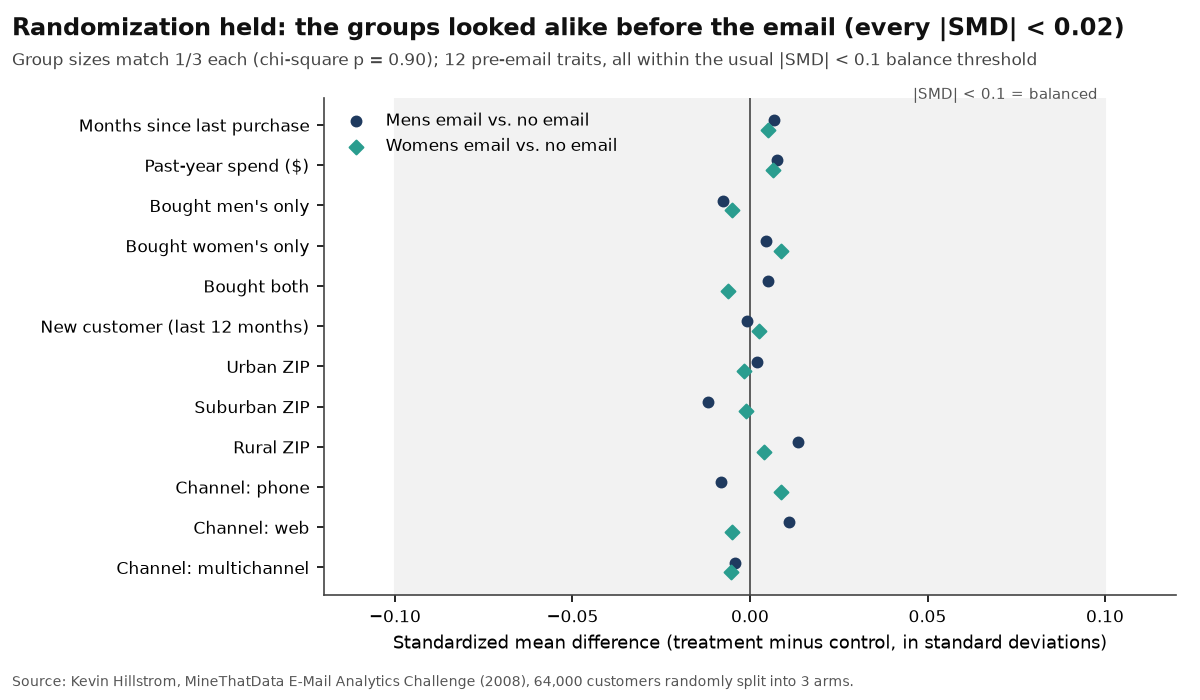

In [4]:
show("balance_smd.png")

## 2. Main effects: each email vs. no email, and Mens vs. Womens

Visits and conversions are 0/1 outcomes, so each comparison is a **two-proportion z-test** (pooled variance for
the test, unpooled for the confidence interval). Below, the Mens-vs-control visit test is computed by hand and
checked against the pipeline's table.

In [5]:
eff = pd.read_csv(R / "main_effects.csv")
t, c = df[df["arm"] == "Mens"]["visit"], df[df["arm"] == "Control"]["visit"]
p_t, p_c = t.mean(), c.mean()
p_pool = (t.sum() + c.sum()) / (len(t) + len(c))
z = (p_t - p_c) / np.sqrt(p_pool * (1 - p_pool) * (1 / len(t) + 1 / len(c)))
se = np.sqrt(p_t * (1 - p_t) / len(t) + p_c * (1 - p_c) / len(c))
lo, hi = p_t - p_c - 1.96 * se, p_t - p_c + 1.96 * se
print(f"Visit rate: Mens {p_t:.2%} vs. no email {p_c:.2%}")
print(f"Lift {100 * (p_t - p_c):+.2f} pts, 95% CI [{100 * lo:.2f}, {100 * hi:.2f}], z = {z:.1f}, p = {2 * stats.norm.sf(abs(z)):.1e}")
row = eff[(eff["comparison"] == "Mens vs Control") & (eff["metric"] == "visit")].iloc[0]
assert np.isclose(row["abs_lift"], p_t - p_c) and np.isclose(row["stat"], z)
print("Matches results/main_effects.csv")

Visit rate: Mens 18.28% vs. no email 10.62%
Lift +7.66 pts, 95% CI [7.00, 8.32], z = 22.5, p = 5.7e-112
Matches results/main_effects.csv


Spend is different: about 99% of customers spent \$0, and the rest spent anywhere up to a few hundred
dollars. The difference in means uses **Welch's t-test** (unequal variances), and the confidence interval is
also **bootstrapped** (10,000 resamples). The bootstrap here uses an exact shortcut: in each resample only the
non-zero rows matter, so it draws how many buyers land in the resample (Binomial) and which ones (uniform). The
check table shows it matches the textbook row bootstrap and the analytic standard error.

In [6]:
display(pd.read_csv(R / "bootstrap_check.csv"))
cols = ["comparison", "metric", "mean_treatment", "mean_baseline", "abs_lift", "ci_low", "ci_high",
        "boot_ci_low", "boot_ci_high", "rel_lift", "p_value", "p_holm", "significant_holm"]
eff[cols]

,arm,analytic_se_of_mean,shortcut_bootstrap_se_10000,row_bootstrap_se_2000,shortcut_vs_row_ratio
0,Control,0.0794,0.0791,0.0794,0.9959
1,Mens,0.1216,0.1222,0.1205,1.0140
2,Womens,0.1034,0.1028,0.1025,1.0030


,comparison,metric,mean_treatment,mean_baseline,abs_lift,ci_low,ci_high,boot_ci_low,boot_ci_high,rel_lift,p_value,p_holm,significant_holm
0,Mens vs Control,visit,0.1828,0.1062,0.0766,0.0700,0.0832,NaN,NaN,0.7214,0.0000,0.0000,True
1,Mens vs Control,conversion,0.0125,0.0057,0.0068,0.0050,0.0086,NaN,NaN,1.1884,0.0000,0.0000,True
2,Mens vs Control,spend,1.4226,0.6528,0.7698,0.4851,1.0545,0.4859,1.0650,1.1793,0.0000,0.0000,True
3,Womens vs Control,visit,0.1514,0.1062,0.0452,0.0389,0.0516,NaN,NaN,0.4261,0.0000,0.0000,True
4,Womens vs Control,conversion,0.0088,0.0057,0.0031,0.0015,0.0047,NaN,NaN,0.5433,0.0002,0.0006,True
5,Womens vs Control,spend,1.0772,0.6528,0.4244,0.1690,0.6799,0.1727,0.6822,0.6502,0.0011,0.0023,True
6,Mens vs Womens,visit,0.1828,0.1514,0.0314,0.0243,0.0384,NaN,NaN,0.2071,0.0000,0.0000,True
7,Mens vs Womens,conversion,0.0125,0.0088,0.0037,0.0017,0.0056,NaN,NaN,0.4180,0.0002,0.0006,True
8,Mens vs Womens,spend,1.4226,1.0772,0.3454,0.0326,0.6583,0.0406,0.6592,0.3207,0.0305,0.0305,True


**Holm correction.** Nine tests (3 comparisons x 3 metrics) are treated as one family; Holm's step-down
method keeps the chance of any false positive at 5%. The sentence below is generated from the table.

In [7]:
def fmt(r):
    if r["metric"] == "spend":
        return f"{r['abs_lift']:+.2f} $/customer (bootstrap 95% CI {r['boot_ci_low']:.2f} to {r['boot_ci_high']:.2f})"
    return f"{100 * r['abs_lift']:+.2f} pts (95% CI {100 * r['ci_low']:.2f} to {100 * r['ci_high']:.2f})"


for _, r in eff.iterrows():
    print(f"{r['comparison']:18s} {r['metric']:10s} {fmt(r):55s} relative {r['rel_lift']:+.0%}  Holm p = {r['p_holm']:.2g}")
print(f"Significant after Holm: {int(eff['significant_holm'].sum())} of {len(eff)}")

Mens vs Control    visit      +7.66 pts (95% CI 7.00 to 8.32)                         relative +72%  Holm p = 5.1e-111
Mens vs Control    conversion +0.68 pts (95% CI 0.50 to 0.86)                         relative +119%  Holm p = 9.1e-13
Mens vs Control    spend      +0.77 $/customer (bootstrap 95% CI 0.49 to 1.06)        relative +118%  Holm p = 5.8e-07
Womens vs Control  visit      +4.52 pts (95% CI 3.89 to 5.16)                         relative +43%  Holm p = 2.5e-43
Womens vs Control  conversion +0.31 pts (95% CI 0.15 to 0.47)                         relative +54%  Holm p = 0.00063
Womens vs Control  spend      +0.42 $/customer (bootstrap 95% CI 0.17 to 0.68)        relative +65%  Holm p = 0.0023
Mens vs Womens     visit      +3.14 pts (95% CI 2.43 to 3.84)                         relative +21%  Holm p = 2.7e-17
Mens vs Womens     conversion +0.37 pts (95% CI 0.17 to 0.56)                         relative +42%  Holm p = 0.00063
Mens vs Womens     spend      +0.35 $/customer (bootst

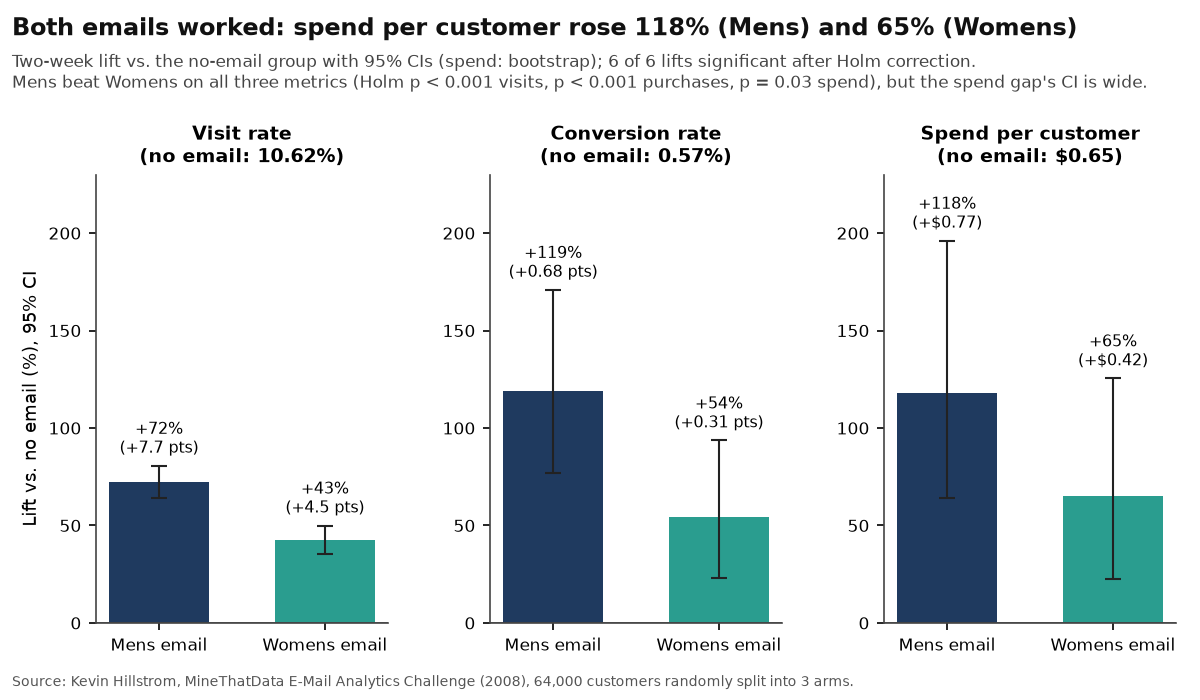

In [8]:
show("lift_by_metric.png")

**Why spend is the noisy metric.** Only a few hundred customers bought anything, so the spend average rests
on a few hundred orders. Spend per buyer was about the same in every group (a descriptive comparison: buyers
are selected after treatment, so it is not randomized), so the revenue lift comes from *more buyers*.

In [9]:
arms = pd.read_csv(R / "arm_metrics.csv")
display(arms)
display(pd.read_csv(R / "spend_per_buyer.csv"))
display(pd.read_csv(R / "spend_lift_decomposition.csv"))
prec = pd.read_csv(R / "metric_precision.csv")
display(prec)
p = prec.set_index("metric")
print(f"95% CI half-width as a share of the Mens lift: visits {p.loc['visit', 'mens_ci_halfwidth_pct_of_lift']:.0%}, "
      f"spend {p.loc['spend', 'mens_ci_halfwidth_pct_of_lift']:.0%}")

,arm,customers,visits,buyers,revenue,visit_rate,conversion_rate,spend_per_customer,spend_sd,spend_per_buyer
0,Control,21306,2262,122,"13,908.3300",0.1062,0.0057,0.6528,11.5882,114.0027
1,Mens,21307,3894,267,"30,311.6900",0.1828,0.0125,1.4226,17.7542,113.5269
2,Womens,21387,3238,189,"23,038.1100",0.1514,0.0088,1.0772,15.1161,121.8948


,arm,buyers,mean_spend_per_buyer,median_spend_per_buyer,sd,ci_low,ci_high,diff_vs_control,p_value_vs_control
0,Control,122,114.0027,88.3650,103.0311,95.7202,132.2852,NaN,NaN
1,Mens,267,113.5269,66.9800,111.6828,100.1308,126.9230,-0.4758,0.9672
2,Womens,189,121.8948,94.7100,105.7703,106.8155,136.9740,7.8921,0.5145


,arm,spend_lift,from_more_buyers,from_order_value,share_from_more_buyers
0,Mens,0.7698,0.7758,-0.0060,1.0077
1,Womens,0.4244,0.3547,0.0697,0.8357


,metric,control_mean,control_sd,coefficient_of_variation,mens_ci_halfwidth_pct_of_lift,womens_ci_halfwidth_pct_of_lift,sample_size_multiplier_vs_visit
0,visit,0.1062,0.3081,2.9016,0.0866,0.1401,1.0000
1,conversion,0.0057,0.0755,13.1775,0.2652,0.5183,20.6245
2,spend,0.6528,11.5882,17.7518,0.3761,0.6003,37.4283


95% CI half-width as a share of the Mens lift: visits 9%, spend 38%


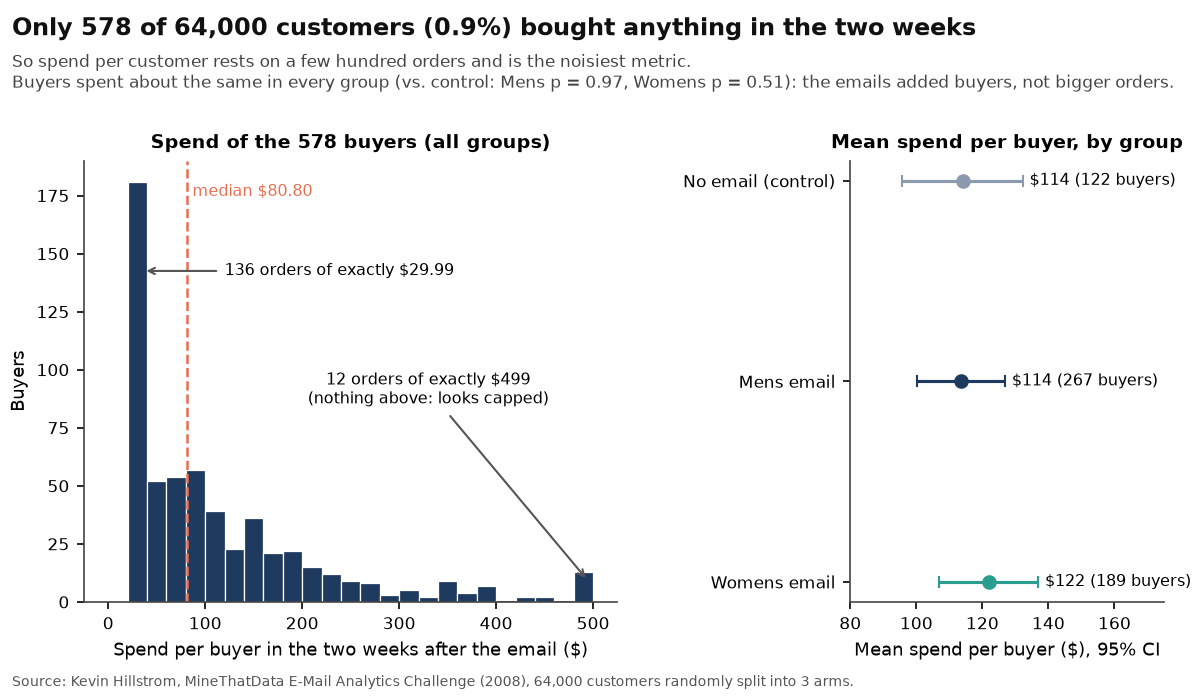

In [10]:
show("spend_distribution.png")

## 3. Power: what could this test detect?

Minimum detectable effect (MDE) at 80% power and a two-sided 5% test: **MDE = (1.96 + 0.84) x standard error**.
The design MDE plugs the control group's variance into both groups at this test's size. A non-significant
result only means "no effect" when the MDE is small relative to the effects that matter.

In [11]:
pw = pd.read_csv(R / "power_mde.csv")
display(pw[["comparison", "metric", "baseline_mean", "mde_design_rel", "mde_realized_rel", "observed_rel_lift",
            "observed_over_design_mde", "verdict"]])
pd.read_csv(R / "sample_size_planning.csv")

,comparison,metric,baseline_mean,mde_design_rel,mde_realized_rel,observed_rel_lift,observed_over_design_mde,verdict
0,Mens vs Control,visit,0.1062,0.0788,0.0893,0.7214,9.1595,detected (significant after Holm)
1,Mens vs Control,conversion,0.0057,0.3577,0.4505,1.1884,3.3226,detected (significant after Holm)
2,Mens vs Control,spend,0.6528,0.4818,0.6234,1.1793,2.4475,detected (significant after Holm)
3,Womens vs Control,visit,0.1062,0.0787,0.0854,0.4261,5.4146,detected (significant after Holm)
4,Womens vs Control,conversion,0.0057,0.3573,0.4025,0.5433,1.5204,detected (significant after Holm)
5,Womens vs Control,spend,0.6528,0.4814,0.5594,0.6502,1.3506,detected (significant after Holm)
6,Mens vs Womens,visit,0.1514,0.0552,0.0668,0.2071,3.7535,detected (significant after Holm)
7,Mens vs Womens,conversion,0.0088,0.2315,0.3155,0.4180,1.8053,detected (significant after Holm)
8,Mens vs Womens,spend,1.0772,0.2917,0.4151,0.3207,1.0992,detected (significant after Holm)


,question,metric,true_difference,customers_per_group,multiple_of_this_test
0,detect a 5% relative lift vs. no email,visit,0.0053,52867,2.4813
1,detect a 10% relative lift vs. no email,visit,0.0106,13217,0.6203
2,detect a 20% relative lift vs. no email,visit,0.0212,3305,0.1551
3,detect a 50% relative lift vs. no email,visit,0.0531,529,0.0248
4,detect a 5% relative lift vs. no email,conversion,0.0003,1090351,51.1758
5,detect a 10% relative lift vs. no email,conversion,0.0006,272588,12.7940
6,detect a 20% relative lift vs. no email,conversion,0.0011,68147,3.1985
7,detect a 50% relative lift vs. no email,conversion,0.0029,10904,0.5118
8,detect a 5% relative lift vs. no email,spend,0.0326,1978717,92.8714
9,detect a 10% relative lift vs. no email,spend,0.0653,494680,23.2179


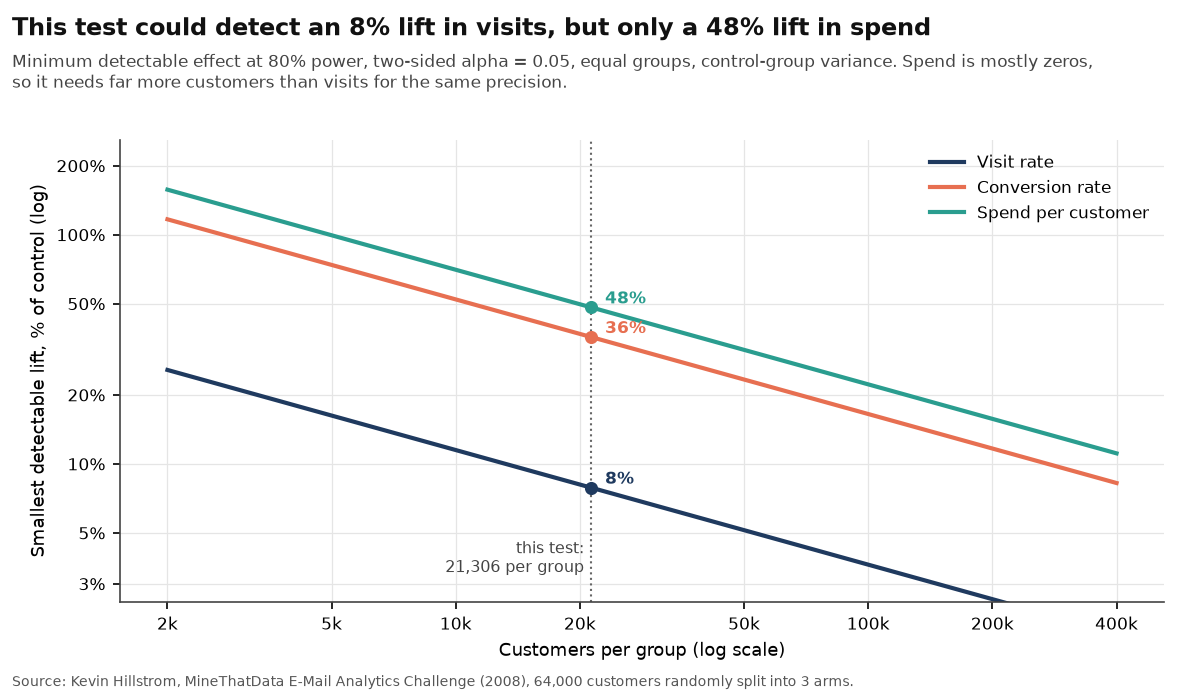

In [12]:
show("power_mde.png")

## 4. Regression adjustment and CUPED

Randomization makes the simple difference in means unbiased. Adding pre-email covariates to an OLS regression
(with HC2 heteroskedasticity-robust standard errors) should leave the estimate almost unchanged and can shrink
its standard error by soaking up outcome variance: the same idea as CUPED, which subtracts theta x (pre-period
metric - its mean). The gain is bounded by how much variance the covariates explain.

In [13]:
import statsmodels.formula.api as smf

m0 = smf.ols("visit ~ C(arm)", data=df).fit(cov_type="HC2")
m1 = smf.ols("visit ~ C(arm) + " + cfg.COVARIATE_FORMULA, data=df).fit(cov_type="HC2")
for name, m in [("unadjusted", m0), ("adjusted", m1)]:
    print(f"{name:10s} Mens effect {100 * m.params['C(arm)[T.Mens]']:+.3f} pts, robust SE {100 * m.bse['C(arm)[T.Mens]']:.4f}, R2 = {m.rsquared:.4f}")
ra = pd.read_csv(R / "regression_adjustment.csv")
ra[["outcome", "comparison", "method", "estimate", "robust_se", "model_r2", "cuped_corr", "se_change_vs_unadjusted",
    "equivalent_extra_sample"]]

unadjusted Mens effect +7.659 pts, robust SE 0.3386, R2 = 0.0079
adjusted   Mens effect +7.615 pts, robust SE 0.3338, R2 = 0.0342


,outcome,comparison,method,estimate,robust_se,model_r2,cuped_corr,se_change_vs_unadjusted,equivalent_extra_sample
0,visit,Mens vs Control,1. Difference in means,0.0766,0.0034,0.0079,NaN,0.0000,0.0000
1,visit,Mens vs Control,2. CUPED (past-year spend),0.0764,0.0034,NaN,0.0652,-0.0022,0.0045
2,visit,Mens vs Control,3. OLS + pre-email covariates,0.0761,0.0033,0.0342,NaN,-0.0140,0.0287
3,visit,Mens vs Control,4. Lin (2013) interacted OLS,0.0761,0.0033,0.0365,NaN,-0.0157,0.0321
4,visit,Womens vs Control,1. Difference in means,0.0452,0.0032,0.0079,NaN,0.0000,0.0000
5,visit,Womens vs Control,2. CUPED (past-year spend),0.0451,0.0032,NaN,0.0652,-0.0020,0.0040
6,visit,Womens vs Control,3. OLS + pre-email covariates,0.0455,0.0032,0.0342,NaN,-0.0127,0.0260
7,visit,Womens vs Control,4. Lin (2013) interacted OLS,0.0455,0.0032,0.0365,NaN,-0.0129,0.0264
8,conversion,Mens vs Control,1. Difference in means,0.0068,0.0009,0.0009,NaN,0.0000,0.0000
9,conversion,Mens vs Control,2. CUPED (past-year spend),0.0068,0.0009,NaN,0.0294,-0.0004,0.0009


## 5. Heterogeneous effects: for whom did it work?

Six subgroup dimensions come from the customer attributes the challenge describes (past purchases, recency,
past-year spend, channel, new vs. existing, ZIP type), with cut-points set by group size, not by outcomes. With 19 subgroups x 3 comparisons x 3 metrics, some subgroup estimates will look large by
chance, so the question "does the effect differ by subgroup?" is tested once per dimension with **Cochran's Q**
(a chi-square test that the subgroup lifts are equal), and those 54 tests are Holm-corrected together.

In [14]:
het = pd.read_csv(R / "heterogeneity_tests.csv")
print(f"Significant after Holm: {int(het['significant_holm'].sum())} of {len(het)} "
      f"(raw p < 0.05: {int(het['significant_raw'].sum())})")
het.head(10)

Significant after Holm: 3 of 54 (raw p < 0.05: 10)


,dimension,comparison,metric,levels,q_stat,df,p_value,lowest_level,lowest_lift,highest_level,highest_lift,p_holm,significant_raw,significant_holm
0,purchase_history,Womens vs Control,visit,3,97.3377,2,0.0000,Mens only,0.0111,Womens only,0.0740,0.0000,True,True
1,purchase_history,Mens vs Womens,visit,3,75.5513,2,0.0000,Womens only,-0.0034,Both,0.0633,0.0000,True,True
2,purchase_history,Mens vs Control,visit,3,23.2366,2,0.0000,Mens only,0.0692,Both,0.1344,0.0005,True,True
3,customer_type,Womens vs Control,conversion,2,6.9541,1,0.0084,Existing customer,0.0009,New customer,0.0053,0.4265,True,False
4,history_bucket,Mens vs Womens,conversion,4,10.6887,3,0.0135,$100-$199,0.0011,$200-$349,0.0091,0.6767,True,False
5,customer_type,Womens vs Control,spend,2,5.6214,1,0.0177,Existing customer,0.1140,New customer,0.7323,0.8694,True,False
6,purchase_history,Mens vs Womens,conversion,3,7.9216,2,0.0190,Womens only,0.0006,Both,0.0097,0.9143,True,False
7,purchase_history,Womens vs Control,conversion,3,7.8455,2,0.0198,Mens only,0.0006,Both,0.0053,0.9300,True,False
8,purchase_history,Mens vs Womens,spend,3,6.3549,2,0.0417,Womens only,-0.0159,Both,1.6631,1.0000,True,False
9,history_bucket,Womens vs Control,spend,4,8.2050,3,0.0420,$200-$349,-0.3231,$350+,0.7001,1.0000,True,False


In [15]:
sub = pd.read_csv(R / "subgroup_effects.csv")
ph = sub[(sub["dimension"] == "purchase_history") & (sub["metric"] == "visit")]
ph.pivot(index="level", columns="comparison", values="abs_lift").mul(100).round(2)

comparison,Mens vs Control,Mens vs Womens,Womens vs Control
level,,,
Both,13.4400,6.3300,7.1100
Mens only,6.9200,5.8100,1.1100
Womens only,7.0600,-0.3400,7.4000


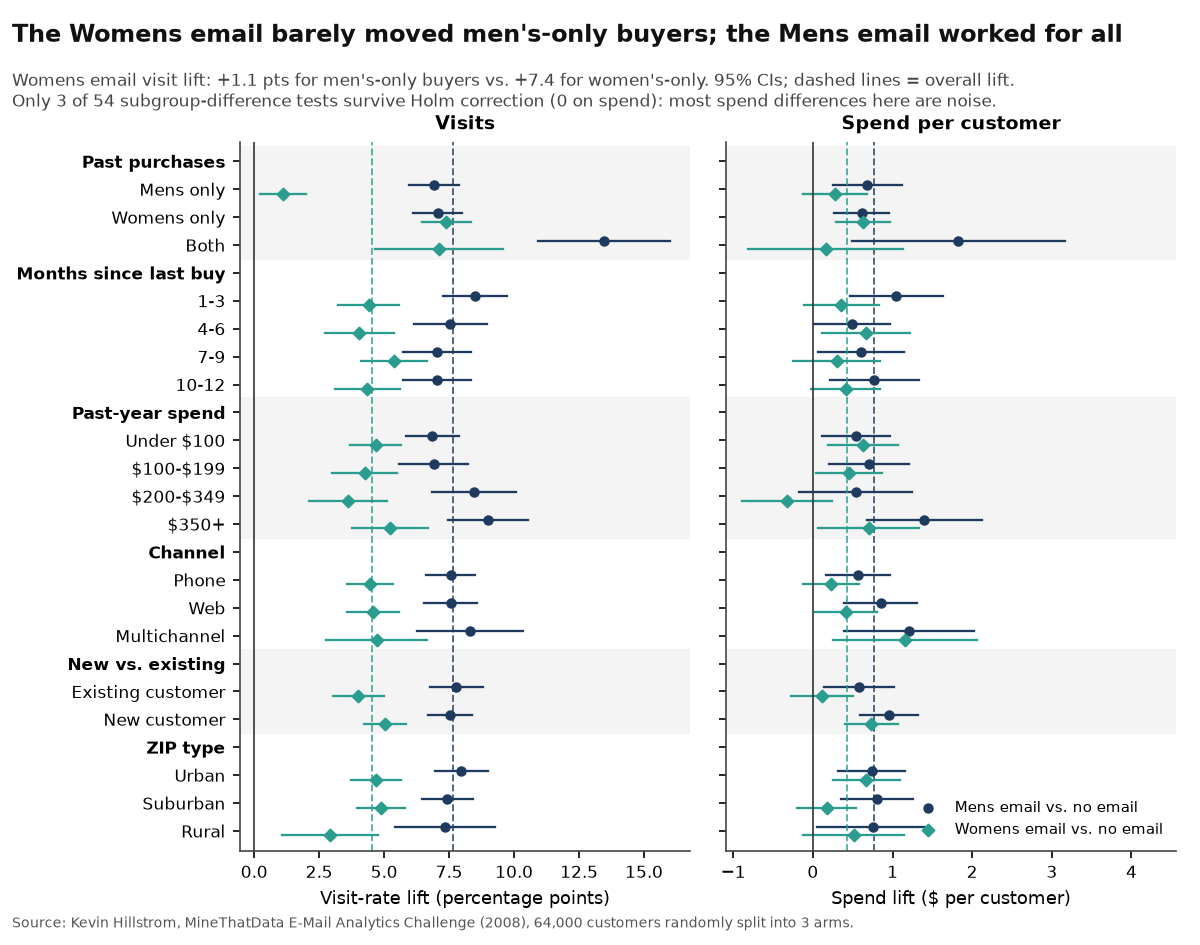

In [16]:
show("subgroup_forest.png")

The strongest pattern, re-estimated as an interaction regression (OLS with HC2 robust SEs). Its Wald test on
the interaction terms reproduces Cochran's Q exactly, a useful cross-check that the two methods agree.

In [17]:
test = pd.read_csv(R / "interaction_test.csv").iloc[0]
print(test["pattern"])
print(f"Wald chi2 = {test['wald_chi2_hc2']:.2f} (df = {test['df']}), Cochran's Q = {test['cochran_q']:.2f}, p = {test['p_value']:.1e}")
pd.read_csv(R / "interaction_model.csv")

Womens vs Control lift in visit differs by purchase_history
Wald chi2 = 97.34 (df = 2), Cochran's Q = 97.34, p = 7.3e-22


,term,coef,robust_se,ci_low,ci_high,p_value
0,Intercept,0.0998,0.0031,0.0938,0.1058,0.0000
1,"C(arm, Treatment(reference='Control'))[T.Mens]",0.0692,0.0049,0.0596,0.0788,0.0000
2,"C(arm, Treatment(reference='Control'))[T.Womens]",0.0111,0.0044,0.0024,0.0197,0.0123
3,"C(purchase_history, Treatment(reference='Mens ...",-0.0040,0.0043,-0.0124,0.0044,0.3508
4,"C(purchase_history, Treatment(reference='Mens ...",0.0807,0.0088,0.0634,0.0981,0.0000
5,"C(arm, Treatment(reference='Control'))[T.Mens]...",0.0014,0.0069,-0.0121,0.0149,0.8365
6,"C(arm, Treatment(reference='Control'))[T.Women...",0.0629,0.0066,0.0500,0.0758,0.0000
7,"C(arm, Treatment(reference='Control'))[T.Mens]...",0.0653,0.0139,0.0381,0.0924,0.0000
8,"C(arm, Treatment(reference='Control'))[T.Women...",0.0600,0.0133,0.0339,0.0861,0.0000


## 6. Who should get which email next time?

A rule learned and scored on the same customers will always look good. So customers are split 50/50 at random:
the **training half** picks the email for each past-purchase group (a segmentation chosen for a business
reason: the emails feature men's vs. women's merchandise), and the **holdout half** estimates what that rule
would have produced,
next to three blanket policies. Email was randomized within every group, so a policy's value is a weighted
average of the matching group-arm means; CIs come from 5,000 bootstrap resamples of the holdout.

In [18]:
display(pd.read_csv(R / "policy_split.csv"))
rule = pd.read_csv(R / "policy_rule.csv")
rule[["level", "train_customers", "train_mens_lift", "train_mens_ci_low", "train_mens_ci_high",
      "train_womens_lift", "train_womens_ci_low", "train_womens_ci_high", "action_label", "reason"]]

,half,Control,Mens,Womens,total
0,train,10554,10681,10765,32000
1,holdout,10752,10626,10622,32000


,level,train_customers,train_mens_lift,train_mens_ci_low,train_mens_ci_high,train_womens_lift,train_womens_ci_low,train_womens_ci_high,action_label,reason
0,Mens only,14306,0.7937,0.2983,1.2892,0.6834,0.1549,1.2118,Mens email,larger training spend lift (+0.79 $/customer v...
1,Womens only,14460,0.4340,-0.0492,0.9173,0.7451,0.2265,1.2637,Womens email,larger training spend lift (+0.75 $/customer v...
2,Both,3234,3.3560,1.2488,5.4632,1.0377,-0.2301,2.3055,Mens email,larger training spend lift (+3.36 $/customer v...


In [19]:
comps = pd.read_csv(R / "policy_holdout_comparisons.csv")
comps[comps["policy"] == "Targeted rule"]

,policy,versus,metric,diff_per_1000,ci_low_per_1000,ci_high_per_1000,boot_se_per_1000,mde80_per_1000,p_value_normal,ci_excludes_zero
12,Targeted rule,No email,visit,77.6286,68.3204,87.0315,4.7573,13.3280,0.0000,True
13,Targeted rule,No email,conversion,6.3673,3.8384,8.8994,1.2948,3.6274,0.0000,True
14,Targeted rule,No email,spend,524.7851,123.8762,929.6555,206.8530,579.5163,0.0112,True
15,Targeted rule,Womens email to everyone,visit,35.3161,28.0877,42.5789,3.7284,10.4455,0.0000,True
16,Targeted rule,Womens email to everyone,conversion,4.5918,2.6328,6.6268,1.0139,2.8406,0.0000,True
17,Targeted rule,Womens email to everyone,spend,419.9823,100.4525,760.3660,169.0947,473.7331,0.0130,True
18,Targeted rule,Mens email to everyone,visit,2.4988,-4.1803,9.3156,3.4414,9.6413,0.4678,False
19,Targeted rule,Mens email to everyone,conversion,-0.9447,-2.7890,0.9127,0.9617,2.6944,0.3260,False
20,Targeted rule,Mens email to everyone,spend,-126.8966,-386.5622,121.0290,129.7025,363.3727,0.3279,False


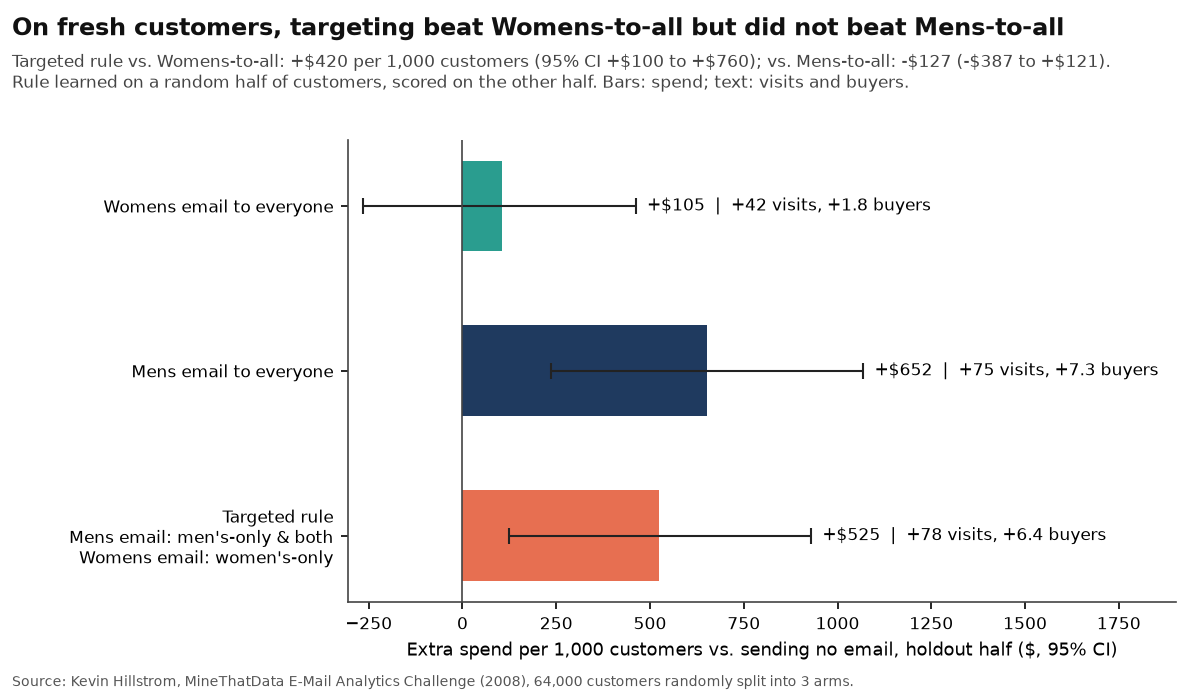

In [20]:
show("policy_holdout.png")

**How much did the training-half estimate shrink on fresh customers?** And is the answer an accident of one
random split? The robustness check repeats the whole split / learn / score procedure 500 times.

In [21]:
display(pd.read_csv(R / "policy_train_vs_holdout.csv"))
display(pd.read_csv(R / "policy_rule_search_diagnostic.csv"))
pd.read_csv(R / "policy_split_robustness_summary.csv")

,policy,metric,train_incremental_per_1000,holdout_incremental_per_1000
0,Womens email to everyone,spend,747.0771,104.8028
1,Mens email to everyone,spend,890.1418,651.6817
2,Targeted rule,spend,"1,030.7146",524.7851


,dimension,rule,train_incremental_spend_per_1000,holdout_incremental_spend_per_1000,used_for_decision,shrinkage
0,purchase_history,Mens only: Mens; Womens only: Womens; Both: Mens,"1,030.7146",524.7851,True,0.4909
1,recency_bucket,1-3: Mens; 4-6: Womens; 7-9: Mens; 10-12: Mens,952.3942,668.9329,False,0.2976
2,history_bucket,Under $100: Womens; $100-$199: Mens; $200-$349...,"1,079.7332",515.8193,False,0.5223
3,channel,Phone: Mens; Web: Mens; Multichannel: Mens,892.3118,649.4946,False,0.2721
4,customer_type,Existing customer: Mens; New customer: Womens,"1,009.5826",303.0429,False,0.6998
5,zip_code,Urban: Womens; Suburban: Mens; Rural: Womens,945.8451,470.7548,False,0.5023


,comparison,splits,share_rule_equals_mens_to_all,mean_per_1000,median_per_1000,p05_per_1000,p95_per_1000,share_of_splits_positive,share_of_splits_negative
0,rule_vs_mens_to_all,500,0.4380,-46.8170,0.0000,-181.7291,2.7079,0.0700,0.4920
1,rule_vs_womens_to_all,500,0.4380,288.9757,301.0320,54.1227,502.4081,0.9760,0.0240
2,rule_vs_no_email,500,0.4380,724.4225,725.0437,474.5570,950.2351,1.0000,0.0000


**ROI under stated assumptions.** Spend is revenue, not profit, and the data has no cost per email. The table
converts each email's full-sample spend lift into gross profit per 1,000 customers emailed for *assumed* gross
margins (30-50%) and *assumed* costs per email (\$0.001-\$0.10). These are assumptions for illustration, not
data.

In [22]:
roi = pd.read_csv(R / "roi_sensitivity.csv")
roi.pivot_table(index=["policy", "assumed_gross_margin"], columns="assumed_cost_per_email",
                values="incremental_gross_profit_per_1000").round(0)

assumed_cost_per_email                          0.0010   0.0100   0.1000
policy                   assumed_gross_margin                           
Mens email to everyone   0.3000               230.0000 221.0000 131.0000
                         0.4000               307.0000 298.0000 208.0000
                         0.5000               384.0000 375.0000 285.0000
Womens email to everyone 0.3000               126.0000 117.0000  27.0000
                         0.4000               169.0000 160.0000  70.0000
                         0.5000               211.0000 202.0000 112.0000

## 7. Summary (generated from results/)

In [23]:
def money(x):
    return f"{'+' if x >= 0 else '-'}${abs(x):,.0f}"


e = eff.set_index(["comparison", "metric"])
c = comps.set_index(["policy", "versus", "metric"])
rob = pd.read_csv(R / "policy_split_robustness_summary.csv").set_index("comparison")
m_s, w_s, mw_s = e.loc[("Mens vs Control", "spend")], e.loc[("Womens vs Control", "spend")], e.loc[("Mens vs Womens", "spend")]
print(f"* Mens email: spend +${m_s['abs_lift']:.2f} per customer ({m_s['rel_lift']:+.0%}), "
      f"95% CI ${m_s['boot_ci_low']:.2f} to ${m_s['boot_ci_high']:.2f}.")
print(f"* Womens email: spend +${w_s['abs_lift']:.2f} per customer ({w_s['rel_lift']:+.0%}), "
      f"95% CI ${w_s['boot_ci_low']:.2f} to ${w_s['boot_ci_high']:.2f}.")
print(f"* Mens minus Womens: +${mw_s['abs_lift']:.2f} per customer, Holm p = {mw_s['p_holm']:.3f}.")
w_mo = sub[(sub["dimension"] == "purchase_history") & (sub["level"] == "Mens only") & (sub["comparison"] == "Womens vs Control") & (sub["metric"] == "visit")].iloc[0]
print(f"* Womens email among men's-only buyers: visits {100 * w_mo['abs_lift']:+.1f} pts (95% CI {100 * w_mo['ci_low']:.1f} to {100 * w_mo['ci_high']:.1f}).")
for base in ["No email", "Womens email to everyone", "Mens email to everyone"]:
    r = c.loc[("Targeted rule", base, "spend")]
    print(f"* Holdout, targeted rule vs. {base}: {money(r['diff_per_1000'])} per 1,000 customers "
          f"(95% CI {money(r['ci_low_per_1000'])} to {money(r['ci_high_per_1000'])}).")
r = rob.loc["rule_vs_mens_to_all"]
print(f"* Over {int(r['splits'])} random splits the rule beat Mens-to-all in {r['share_of_splits_positive']:.0%} of splits "
      f"(mean {money(r['mean_per_1000'])} per 1,000).")

* Mens email: spend +$0.77 per customer (+118%), 95% CI $0.49 to $1.06.
* Womens email: spend +$0.42 per customer (+65%), 95% CI $0.17 to $0.68.
* Mens minus Womens: +$0.35 per customer, Holm p = 0.030.
* Womens email among men's-only buyers: visits +1.1 pts (95% CI 0.2 to 2.0).
* Holdout, targeted rule vs. No email: +$525 per 1,000 customers (95% CI +$124 to +$930).
* Holdout, targeted rule vs. Womens email to everyone: +$420 per 1,000 customers (95% CI +$100 to +$760).
* Holdout, targeted rule vs. Mens email to everyone: -$127 per 1,000 customers (95% CI -$387 to +$121).
* Over 500 random splits the rule beat Mens-to-all in 7% of splits (mean -$47 per 1,000).
